# Noria · 02 — Data preparation

Session 2: cleaning, created variables, feature sets and the train / validation / test split.
**No model is trained in this notebook.**

All the logic lives in `src/` (this notebook only calls it and displays the results):
- `src/config.py`: paths, parameters and the three feature sets
- `src/data.py`: filtering, cleaning, created variables, rare-category grouping, split
- `src/preprocessing.py`: the scikit-learn preprocessing that learns from the data (fit on train only)

Reference: `docs/project-brief.md`, sections 4 and 5.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data, preprocessing

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=120, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{name}")

## 1. Filtering and cleaning (deterministic, before the split)

In [2]:
raw = data.load_raw()
df, report = data.prepare(raw)

print("Rows at each filtering step:")
display(report["row_counts"])
print(f"Default rate after filtering: {df[config.TARGET].mean() * 100:.2f}%")
print(f"Housing columns dropped: {len(report['dropped_housing_columns'])}")
print(f"Columns: {raw.shape[1]} raw -> {df.shape[1]} prepared")

Rows at each filtering step:


,rows,removed
step,,
raw,307511,0
NAME_CONTRACT_TYPE == 'Cash loans',278232,29279
CODE_GENDER != 'XNA',278232,0
NAME_FAMILY_STATUS != 'Unknown',278232,0


Default rate after filtering: 8.35%
Housing columns dropped: 47
Columns: 122 raw -> 86 prepared


In [3]:
rare = pd.DataFrame(
    [(col, cat, int((raw.loc[raw['NAME_CONTRACT_TYPE'] == config.KEPT_CONTRACT_TYPE, col] == cat).sum()))
     for col, cats in report["rare_groups"].items() for cat in cats],
    columns=["column", "category grouped into 'Other'", "rows"],
)
print(f"Rare categories (< {config.RARE_CATEGORY_THRESHOLD:.1%} of rows) grouped into '{config.RARE_LABEL}':")
display(rare)
display(rare.groupby("column")["rows"].agg(categories="size", rows="sum"))

Rare categories (< 0.1% of rows) grouped into 'Other':


,column,category grouped into 'Other',rows
0,NAME_TYPE_SUITE,Group of people,243
1,NAME_INCOME_TYPE,Student,15
2,NAME_INCOME_TYPE,Unemployed,15
3,NAME_INCOME_TYPE,Maternity leave,2
4,NAME_EDUCATION_TYPE,Academic degree,146
5,ORGANIZATION_TYPE,Mobile,268
6,ORGANIZATION_TYPE,Legal Services,259
7,ORGANIZATION_TYPE,Cleaning,236
8,ORGANIZATION_TYPE,Transport: type 1,179
9,ORGANIZATION_TYPE,Industry: type 6,97


,categories,rows
column,,
NAME_EDUCATION_TYPE,1,146
NAME_INCOME_TYPE,3,32
NAME_TYPE_SUITE,1,243
ORGANIZATION_TYPE,11,1393


## 2. Created variables

In [4]:
print("IS_PENSIONER = 1 rows by NAME_INCOME_TYPE before grouping (DAYS_EMPLOYED = 365243):")
cash = raw[raw["NAME_CONTRACT_TYPE"] == config.KEPT_CONTRACT_TYPE]
anomaly = cash["DAYS_EMPLOYED"] == config.DAYS_EMPLOYED_ANOMALY
display(cash.loc[anomaly, "NAME_INCOME_TYPE"].value_counts().rename("rows").to_frame())
print(f"IS_PENSIONER = 1: {df['IS_PENSIONER'].sum():,} rows; "
      f"DAYS_EMPLOYED now missing on {df['DAYS_EMPLOYED'].isna().sum():,} rows")
print(df.groupby("IS_PENSIONER")[config.TARGET].agg(rows="size", default_rate="mean")
        .assign(default_rate=lambda t: (t["default_rate"] * 100).round(2)).to_string())

IS_PENSIONER = 1 rows by NAME_INCOME_TYPE before grouping (DAYS_EMPLOYED = 365243):


,rows
NAME_INCOME_TYPE,
Pensioner,51993
Unemployed,15


IS_PENSIONER = 1: 52,008 rows; DAYS_EMPLOYED now missing on 52,008 rows
                rows  default_rate
IS_PENSIONER                      
0             226224          9.00
1              52008          5.48


In [5]:
created = list(config.YEARS_FROM_DAYS) + [
    "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM", "INCOME_PER_PERSON", "EMPLOYMENT_AGE_RATIO"]
checks = pd.DataFrame({
    "missing": df[created].isna().sum(),
    "infinite": np.isinf(df[created]).sum(),
    "min": df[created].min().round(3),
    "median": df[created].median().round(3),
    "max": df[created].max().round(3),
})
display(checks)
assert checks["infinite"].sum() == 0, "a division produced inf"

,missing,infinite,min,median,max
AGE_YEARS,0,0,20.504,43.461,6.899700e+01
EMPLOYMENT_YEARS,52008,0,0.000,4.589,4.904000e+01
REGISTRATION_YEARS,0,0,0.000,12.381,6.754800e+01
ID_PUBLISH_YEARS,0,0,0.000,9.018,1.970400e+01
PHONE_CHANGE_YEARS,1,0,0.000,2.149,1.175100e+01
CREDIT_INCOME_RATIO,0,0,0.005,3.500,8.473700e+01
ANNUITY_INCOME_RATIO,12,0,0.000,0.172,1.876000e+00
CREDIT_TERM,12,0,8.037,20.677,4.530500e+01
INCOME_PER_PERSON,0,0,2812.500,75000.000,3.900000e+07
EMPLOYMENT_AGE_RATIO,52008,0,0.000,0.120,7.290000e-01


## 3. Train / validation / test split (70 / 15 / 15, stratified on TARGET, random_state = 42)

In [6]:
train, val, test = data.split(df)
paths = data.save_splits(train, val, test)
for name, path in paths.items():
    print(f"Saved: {path.relative_to(config.ROOT)}")

split_summary = pd.DataFrame({
    name: {
        "rows": len(part),
        "share (%)": round(len(part) / len(df) * 100, 2),
        "defaults": int(part[config.TARGET].sum()),
        "default rate (%)": round(part[config.TARGET].mean() * 100, 3),
        "SK_ID_CURR kept": config.ID_COL in part.columns,
        "CODE_GENDER kept": config.FAIRNESS_COL in part.columns,
    }
    for name, part in {"train": train, "val": val, "test": test}.items()
}).T
split_summary

Saved: data/processed/train.parquet
Saved: data/processed/val.parquet
Saved: data/processed/test.parquet


,rows,share (%),defaults,default rate (%),SK_ID_CURR kept,CODE_GENDER kept
train,194762,70.0,16255,8.346,True,True
val,41735,15.0,3483,8.346,True,True
test,41735,15.0,3483,8.346,True,True


In [7]:
ids = {name: set(part[config.ID_COL]) for name, part in {"train": train, "val": val, "test": test}.items()}
overlaps = {
    "train & val": len(ids["train"] & ids["val"]),
    "train & test": len(ids["train"] & ids["test"]),
    "val & test": len(ids["val"] & ids["test"]),
}
print("SK_ID_CURR shared between files:", overlaps)
print("All prepared rows assigned exactly once:",
      sum(len(s) for s in ids.values()) == len(df) == len(set().union(*ids.values())))
assert sum(overlaps.values()) == 0

SK_ID_CURR shared between files: {'train & val': 0, 'train & test': 0, 'val & test': 0}
All prepared rows assigned exactly once: True


## 4. Feature sets (`src/config.py`)

In [8]:
counts = pd.DataFrame({
    name: dict(zip(["categorical", "binary flags", "continuous"],
                   map(len, preprocessing.split_column_types(train, feats))), total=len(feats))
    for name, feats in config.FEATURE_SETS.items()
}).T
display(counts)

history = set(config.HISTORY_FEATURES)
for name, feats in config.FEATURE_SETS.items():
    assert set(feats) <= set(train.columns), f"{name}: unknown column"
    assert config.FAIRNESS_COL not in feats, f"{name}: gender must not be a feature"
print("History columns in client:", sorted(history & set(config.CLIENT_FEATURES)))
print("History columns in bank_no_history:", sorted(history & set(config.BANK_NO_HISTORY_FEATURES)))
print("bank_with_history - bank_no_history:",
      sorted(set(config.BANK_WITH_HISTORY_FEATURES) - set(config.BANK_NO_HISTORY_FEATURES)))
print("CODE_GENDER in any feature set:", any(config.FAIRNESS_COL in f for f in config.FEATURE_SETS.values()))

,categorical,binary flags,continuous,total
client,2,1,6,9
bank_no_history,9,31,24,64
bank_with_history,9,31,33,73


History columns in client: []
History columns in bank_no_history: []
bank_with_history - bank_no_history: ['AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
CODE_GENDER in any feature set: False


In [9]:
print("Client features and how each one is computed from the public form:")
display(pd.Series(config.CLIENT_FORM_FORMULAS, name="from the form").to_frame())
print("Columns excluded from the bank feature sets:")
display(pd.Series(config.EXCLUDED_COLUMNS, name="reason").to_frame())

Client features and how each one is computed from the public form:


,from the form
AGE_YEARS,age
NAME_FAMILY_STATUS,family_status
CNT_CHILDREN,children
NAME_INCOME_TYPE,employment_type mapped to a dataset category
EMPLOYMENT_YEARS,employment_length (NaN when IS_PENSIONER = 1)
IS_PENSIONER,"1 if employment_type has no current job, else 0"
CREDIT_INCOME_RATIO,amount / income
CREDIT_TERM,"amount / annuity = duration, with annuity = am..."
ANNUITY_INCOME_RATIO,(amount / duration) / income


Columns excluded from the bank feature sets:


,reason
SK_ID_CURR,"identifier, carries no information about the a..."
TARGET,label to predict
CODE_GENDER,"gender excluded from all models, kept only for..."
NAME_CONTRACT_TYPE,constant after keeping cash loans only
DAYS_BIRTH,replaced by AGE_YEARS
DAYS_EMPLOYED,replaced by EMPLOYMENT_YEARS and IS_PENSIONER
DAYS_REGISTRATION,replaced by REGISTRATION_YEARS
DAYS_ID_PUBLISH,replaced by ID_PUBLISH_YEARS
DAYS_LAST_PHONE_CHANGE,replaced by PHONE_CHANGE_YEARS
WEEKDAY_APPR_PROCESS_START,"describes when the file was entered, not the a..."


In [10]:
# The client form only offers some employment types: categories the model will see for NAME_INCOME_TYPE.
display(train["NAME_INCOME_TYPE"].value_counts().rename("train rows").to_frame())

,train rows
NAME_INCOME_TYPE,
Working,99836
Commercial associate,44612
Pensioner,36430
State servant,13861
Other,23


## 5. New ratios (train set only)

Distributions and default rates are computed on **train only**, so that validation and test stay untouched.

In [11]:
ratios = ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM", "INCOME_PER_PERSON", "EMPLOYMENT_AGE_RATIO"]
display(train[ratios].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max
CREDIT_INCOME_RATIO,194762.0,4.154,2.742,0.005,0.600,2.190,3.504,5.463,13.333,4.922700e+01
ANNUITY_INCOME_RATIO,194756.0,0.189,0.095,0.000,0.044,0.122,0.172,0.237,0.490,1.571000e+00
CREDIT_TERM,194756.0,21.799,8.215,8.037,8.427,14.964,20.677,27.844,37.805,4.530500e+01
INCOME_PER_PERSON,194762.0,93263.585,113145.439,3375.000,18000.000,49500.000,75150.000,112500.000,337500.000,3.900000e+07
EMPLOYMENT_AGE_RATIO,158323.0,0.158,0.134,0.000,0.008,0.057,0.120,0.222,0.593,7.290000e-01


Figure saved: reports/figures/06_ratio_distributions.png


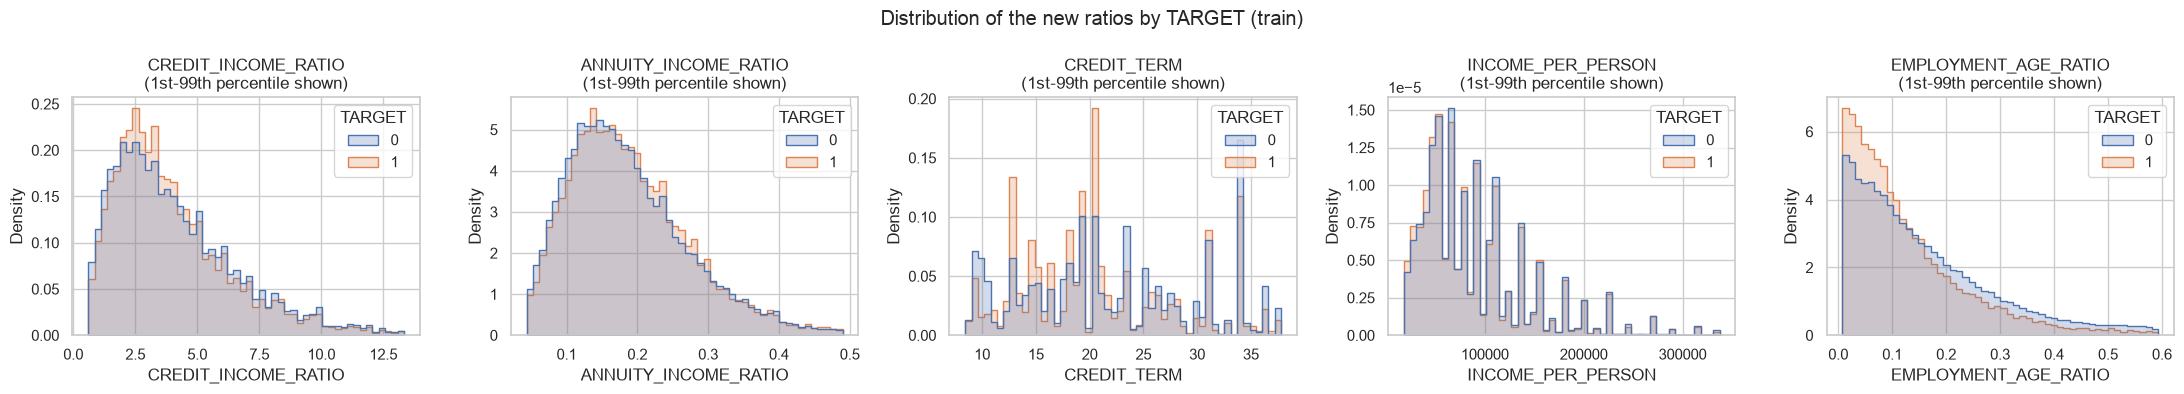

In [12]:
fig, axes = plt.subplots(1, len(ratios), figsize=(22, 4))
for ax, col in zip(axes, ratios):
    s = train[col].dropna()
    lo, hi = s.quantile([0.01, 0.99])
    sns.histplot(data=train[train[col].between(lo, hi)], x=col, hue=config.TARGET,
                 stat="density", common_norm=False, bins=50, element="step", ax=ax)
    ax.set_title(f"{col}\n(1st-99th percentile shown)")
fig.suptitle("Distribution of the new ratios by TARGET (train)")
fig.tight_layout()
save(fig, "06_ratio_distributions.png")
plt.show()

In [13]:
def default_rate_by_decile(col):
    bins = pd.qcut(train[col], q=10, duplicates="drop", precision=3)
    t = train.groupby(bins, observed=True)[config.TARGET].agg(rows="size", default_rate="mean")
    t["default_rate"] = (t["default_rate"] * 100).round(2)
    return t

term_table = default_rate_by_decile("CREDIT_TERM")
dti_table = default_rate_by_decile("ANNUITY_INCOME_RATIO")
print("Default rate by CREDIT_TERM decile (train):")
display(term_table)
print("Default rate by ANNUITY_INCOME_RATIO decile (train):")
display(dti_table)

Default rate by CREDIT_TERM decile (train):


,rows,default_rate
CREDIT_TERM,,
"(8.036000000000001, 10.234]",19487,4.85
"(10.234, 13.747]",19465,12.08
"(13.747, 16.489]",19493,10.23
"(16.489, 19.099]",19488,8.70
"(19.099, 20.677]",19535,12.59
"(20.677, 23.496]",19444,8.95
"(23.496, 26.261]",19418,6.05
"(26.261, 30.813]",19703,6.84
"(30.813, 34.075]",19322,7.26


Default rate by ANNUITY_INCOME_RATIO decile (train):


,rows,default_rate
ANNUITY_INCOME_RATIO,,
"(-0.000776, 0.0868]",19482,7.57
"(0.0868, 0.112]",19471,7.53
"(0.112, 0.132]",19475,8.13
"(0.132, 0.152]",19480,8.39
"(0.152, 0.172]",19470,8.49
"(0.172, 0.194]",19477,8.38
"(0.194, 0.221]",19475,8.62
"(0.221, 0.255]",19475,9.00
"(0.255, 0.31]",19475,9.20


Figure saved: reports/figures/07_default_rate_by_term_and_dti.png


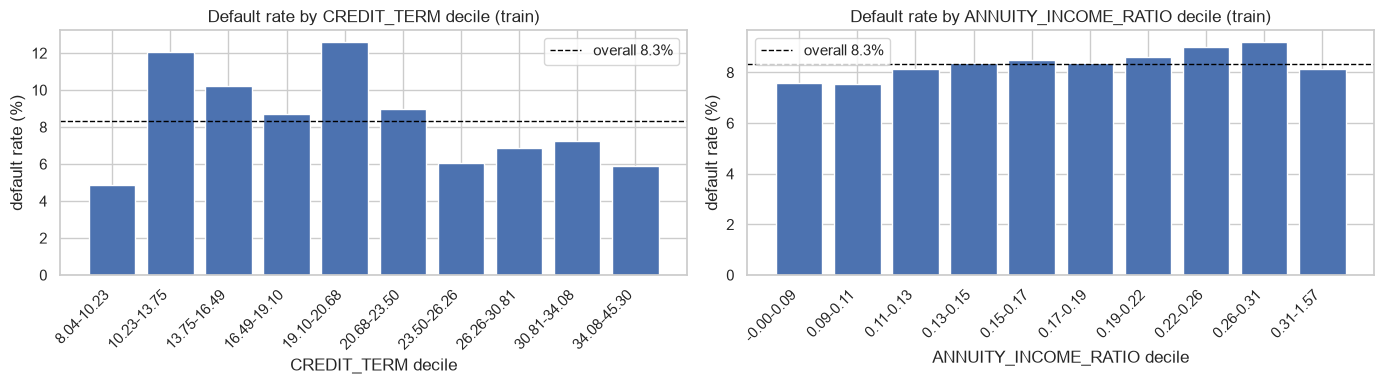

In [14]:
overall = train[config.TARGET].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (col, t) in zip(axes, {"CREDIT_TERM": term_table, "ANNUITY_INCOME_RATIO": dti_table}.items()):
    labels = [f"{iv.left:.2f}-{iv.right:.2f}" for iv in t.index]
    ax.bar(labels, t["default_rate"], color="#4C72B0")
    ax.axhline(overall, color="black", ls="--", lw=1, label=f"overall {overall:.1f}%")
    ax.set_title(f"Default rate by {col} decile (train)")
    ax.set_ylabel("default rate (%)")
    ax.set_xlabel(f"{col} decile")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend()
fig.tight_layout()
save(fig, "07_default_rate_by_term_and_dti.png")
plt.show()

### 5.1 Unit check: income vs annuity

The brief assumes `AMT_INCOME_TOTAL` is **annual** and the form income **monthly** (×12 in the API).
`CREDIT_TERM` (median ≈ 20, range 8-45) only reads as a number of months if `AMT_ANNUITY` is a **monthly** payment.
If both assumptions held, `AMT_ANNUITY > AMT_INCOME_TOTAL / 12` would mean a monthly payment larger than the monthly income.

In [15]:
r = train["ANNUITY_INCOME_RATIO"].dropna()
print(f"Rows where AMT_ANNUITY > AMT_INCOME_TOTAL / 12: {(r > 1 / 12).mean() * 100:.1f}% of train")
print(f"Median ANNUITY_INCOME_RATIO: {r.median():.3f}  "
      f"(x12 = {r.median() * 12:.2f} if annuity is monthly and income annual)")

Rows where AMT_ANNUITY > AMT_INCOME_TOTAL / 12: 91.1% of train
Median ANNUITY_INCOME_RATIO: 0.172  (x12 = 2.07 if annuity is monthly and income annual)


## 6. Preprocessing pipeline check

Fit on **train only**, then transform validation. No model is trained: this only checks that the pipeline runs.

In [16]:
rows = []
for name, feats in config.FEATURE_SETS.items():
    for scale in (False, True):
        pre = preprocessing.build_preprocessor(train, feats, scale=scale)
        pre.fit(train[feats])                 # fitted on train only
        X_val = pre.transform(val[feats])     # val is only transformed
        rows.append({"feature set": name, "scale": scale, "input columns": len(feats),
                     "output columns": X_val.shape[1], "val rows": X_val.shape[0],
                     "NaN after transform": int(X_val.isna().sum().sum())})
pipeline_check = pd.DataFrame(rows)
display(pipeline_check)
assert (pipeline_check["NaN after transform"] == 0).all()

,feature set,scale,input columns,output columns,val rows,NaN after transform
0,client,False,9,17,41735,0
1,client,True,9,17,41735,0
2,bank_no_history,False,64,152,41735,0
3,bank_no_history,True,64,152,41735,0
4,bank_with_history,False,73,161,41735,0
5,bank_with_history,True,73,161,41735,0


In [17]:
pre = preprocessing.build_preprocessor(train, config.CLIENT_FEATURES).fit(train[config.CLIENT_FEATURES])
cap = pre.named_transformers_["continuous"].named_steps["cap"]
print("Capping bounds learned on train (client features):")
display(pd.DataFrame({"1st percentile": cap.lower_, "99th percentile": cap.upper_},
                     index=cap.feature_names_in_).round(3))

Capping bounds learned on train (client features):


,1st percentile,99th percentile
AGE_YEARS,23.110,67.032
CNT_CHILDREN,0.000,3.000
EMPLOYMENT_YEARS,0.307,31.227
CREDIT_INCOME_RATIO,0.600,13.333
CREDIT_TERM,8.427,37.805
ANNUITY_INCOME_RATIO,0.044,0.490


## Findings

1. **Filtering**: 307,511 → 278,232 rows after keeping `Cash loans` (29,279 revolving loans removed). The `CODE_GENDER = "XNA"` (4) and `NAME_FAMILY_STATUS = "Unknown"` (2) rows were all revolving loans, so those two filters remove 0 rows. Default rate after filtering: 8.35%. Columns: 122 → 86 (47 housing columns dropped, 11 created).
2. **IS_PENSIONER**: 52,008 rows (51,993 `Pensioner` + 15 `Unemployed`), default rate 5.48% vs 9.00% for the others. `EMPLOYMENT_YEARS` and `EMPLOYMENT_AGE_RATIO` are missing on exactly these 52,008 rows. No division produced an infinite value. `ANNUITY_INCOME_RATIO` and `CREDIT_TERM` are missing on 12 rows (missing `AMT_ANNUITY`).
3. **Rare categories** (< 0.1%) grouped into "Other": 16 categories over 4 columns. `ORGANIZATION_TYPE` 11 categories (1,393 rows), `NAME_TYPE_SUITE` 1 (243), `NAME_EDUCATION_TYPE` 1 (`Academic degree`, 146), `NAME_INCOME_TYPE` 3 (`Student` 15, `Unemployed` 15, `Maternity leave` 2). `NAME_INCOME_TYPE = "Other"` has only 23 rows in train.
4. **Split**: train 194,762 / val 41,735 / test 41,735 (70 / 15 / 15). The default rate is 8.346% in all three (16,255 / 3,483 / 3,483 defaults). No `SK_ID_CURR` is shared between two files, and every prepared row is assigned exactly once. `SK_ID_CURR` and `CODE_GENDER` are kept in each file.
5. **Feature sets**: client 9 (2 categorical, 1 flag, 6 continuous), bank without history 64 (9 / 31 / 24), bank with history 73 (+3 `EXT_SOURCE` and +6 `AMT_REQ_CREDIT_BUREAU_*`). No history column in the first two sets, and `CODE_GENDER` in none. After preprocessing: 17, 152 and 161 columns.
6. **CREDIT_TERM** (train median 20.68, 1st-99th percentile 8.43-37.81) is not monotonic with default. The shortest decile has the lowest rate (4.85%), the 10.2-13.7 decile 12.08%, and the 19.1-20.7 decile peaks at 12.59%. Terms above 23.5 range between 5.90% and 7.26%.
7. **ANNUITY_INCOME_RATIO** (train median 0.172) has a weak gradient: 7.57% in the lowest decile up to 9.20% in the 9th, then 8.14% in the top decile.
8. **Units**: in 91.1% of train rows, `AMT_ANNUITY` is larger than `AMT_INCOME_TOTAL / 12`. The brief's assumptions (annual income, ×12 in the API) and the reading of `CREDIT_TERM` as months (monthly annuity) cannot both be true. To be settled before the client form maps its inputs.
9. **Pipeline**: fitted on train only, it transforms validation for the three sets (with and without scaling), with 0 missing values after transform.